In [ ]:
# =============================================================================

import json, time, unicodedata
from collections import defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix)

SEED = 42
NEAR_THR = 0.8          # word-Jaccard above this counts as a near duplicate

In [ ]:
!rm -rf /content/drive/*
!rmdir /content/drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

rmdir: failed to remove '/content/drive': No such file or directory
Mounted at /content/drive


In [ ]:
# ---------------------------------------------------------------- 0. paths
# Colab: point DATA_DIR at your Drive copy of the dataset folder. If T1/X0 have
# already run in this session, both are inherited and this block is a no-op.
if "DATA_DIR" not in globals():
    DATA_DIR = Path("/content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset")
if "OUTDIR" not in globals():
    OUTDIR = Path("/content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset")
DATA_DIR, OUTDIR = Path(DATA_DIR), Path(OUTDIR)
OUTDIR.mkdir(parents=True, exist_ok=True)
assert (DATA_DIR / "train.csv").exists(), (
    f"no train.csv under {DATA_DIR}. Set DATA_DIR to the folder holding "
    f"train.csv / test.csv / label_mapping.json.")

tr = pd.read_csv(DATA_DIR / "train.csv")
te = pd.read_csv(DATA_DIR / "test.csv")
_lm = json.loads((DATA_DIR / "label_mapping.json").read_text(encoding="utf-8"))
id_to_label = [_lm["id_to_label"][str(i)] for i in range(_lm["num_classes"])]
NUM_CLASSES = len(id_to_label)
print(f"train {len(tr):,} rows | test {len(te):,} rows | {NUM_CLASSES} classes")

train 55,999 rows | test 11,999 rows | 5 classes


In [ ]:
# ------------------------------------- 1. unique train rows, unique test index
# drop_duplicates on text_clean, NOT on Sentence: cleaning collapses 1,516
# previously distinct sentences, and those collapsed pairs are what leak.
_tr_u = tr.drop_duplicates(subset="text_clean", keep="first")
Xtr_txt = _tr_u["text_clean"].astype(str).tolist()
ytr = _tr_u["label_id"].to_numpy()
assert len(_tr_u) == 40902, (
    f"expected 40,902 unique train comments, got {len(_tr_u):,}. If this "
    f"differs, your train.csv is not the audited 80K split.")

if "KEEP" in globals():
    _keep = np.asarray(KEEP)
    print(f"   reusing KEEP from this session ({len(_keep):,} comments)")
else:
    _keep = te.drop_duplicates(subset="text_clean", keep="first").index.to_numpy()
    print(f"   built KEEP locally ({len(_keep):,} comments)")
assert len(_keep) == 8764, f"expected 8,764 unique test comments, got {len(_keep):,}"

Xte_txt = te["text_clean"].astype(str).iloc[_keep].tolist()
yte = te["label_id"].to_numpy()[_keep]
assert not (set(Xte_txt) & set(Xtr_txt)), "exact-text overlap between splits"
print(f"training on {len(Xtr_txt):,} unique | scoring on {len(yte):,} unique")

   built KEEP locally (8,764 comments)
training on 40,902 unique | scoring on 8,764 unique


In [ ]:
# --------------------------------- 1b. near-duplicate mask (reusable by all arms)
# prepare_dataset.py never strips punctuation (its last step is whitespace
# collapse), so "ভালো লাগছে।" and "ভালো লাগছে" are different strings and can land
# on opposite sides of the split while being the same comment. 237 test comments
# (2.70%) are punctuation-identical to a training comment. Character n-grams and
# subword transformers read straight through that.
#
# This is NOT a reason to rebuild the dataset six days out. It is a reason to
# report a second column. The mask is saved so the transformer and Keras arms can
# report the same column with one extra line each.
_MASKF = OUTDIR / "test_nearest_train_jaccard.npy"
if _MASKF.exists() and len(np.load(_MASKF)) == len(yte):
    _jac = np.load(_MASKF)
    print(f"   near-duplicate mask loaded from {_MASKF.name}")
else:
    _t0 = time.time()
    _P = {c for c in map(chr, range(0x110000))
          if unicodedata.category(c).startswith("P")} | {"।", "॥"}

    def _key(t):
        return [w for w in ("".join(c for c in unicodedata.normalize("NFC", t)
                                    if c not in _P)).split() if w]

    _trs = [set(_key(t)) for t in Xtr_txt]
    _tes = [set(_key(t)) for t in Xte_txt]
    _df = defaultdict(int)
    for s in _trs:
        for w in s:
            _df[w] += 1
    _cap = int(0.02 * len(_trs))          # skip tokens too common to be evidence
    _inv = defaultdict(list)
    for i, s in enumerate(_trs):
        for w in s:
            if _df[w] <= _cap:
                _inv[w].append(i)
    _jac = np.zeros(len(_tes))
    for qi, qs in enumerate(_tes):
        if not qs:
            continue
        cand = set()
        for w in sorted((w for w in qs if w in _inv), key=lambda w: _df[w])[:15]:
            cand.update(_inv[w])
        bv = 0.0
        for ci in cand:
            cs = _trs[ci]
            it = len(qs & cs)
            if it:
                j = it / (len(qs) + len(cs) - it)
                if j > bv:
                    bv = j
        _jac[qi] = bv
    np.save(_MASKF, _jac)
    print(f"   near-duplicate mask computed in {time.time()-_t0:.0f}s "
          f"-> {_MASKF.name}")
CLEAN = _jac < NEAR_THR
print(f"   clean subset: {int(CLEAN.sum()):,} of {len(yte):,} comments have no "
      f">= {NEAR_THR} Jaccard match in training "
      f"({int((~CLEAN).sum()):,} excluded)")

   near-duplicate mask loaded from test_nearest_train_jaccard.npy
   clean subset: 8,391 of 8,764 comments have no >= 0.8 Jaccard match in training (373 excluded)


In [ ]:
# ------------------------------------------------------- 2. features
# Word n-grams catch whole-word cues; character n-grams are what make this
# competitive on Bangla, because they survive inflection, spelling variation and
# code-mixed romanisation. char_wb keeps n-grams inside word boundaries.
#
# lowercase=False: Bangla has no case, and lowercasing would only mangle the
# romanised Banglish fragments, which are exactly the hard cases.
# token_pattern: see the tokenizer trap in the header. Do not restore the default.
t0 = time.time()
vec_w = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                        sublinear_tf=True, lowercase=False,
                        token_pattern=r"(?u)\S+")
vec_c = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                        sublinear_tf=True, lowercase=False)

Aw = vec_w.fit_transform(Xtr_txt)          # fit on TRAIN ONLY
Ac = vec_c.fit_transform(Xtr_txt)
Bw = vec_w.transform(Xte_txt)              # transform, never fit_transform
Bc = vec_c.transform(Xte_txt)
Xtr = hstack([Aw, Ac]).tocsr()
Xte = hstack([Bw, Bc]).tocsr()
print(f"features: word {Aw.shape[1]:,} + char {Ac.shape[1]:,} "
      f"= {Xtr.shape[1]:,}  ({time.time()-t0:.1f}s)")
# Guard the tokenizer trap directly, rather than by guessing a feature count.
# With the correct pattern this is 86,109 word features; with sklearn's default
# it collapses to 39,957 fragments, and the probe below is what tells them apart.
_probe = "ভাবিটাকে সুন্দর লাগছে"
_toks = vec_w.build_analyzer()(_probe)
assert "ভাবিটাকে" in _toks, (
    f"the word analyzer shredded Bangla: {_probe!r} -> {_toks[:6]}. "
    f"token_pattern must be r'(?u)\\S+'; sklearn's default r'(?u)\\b\\w\\w+\\b' "
    f"drops every vowel sign and virama. See the header.")
print(f"   tokenizer probe OK: {_probe!r} -> {_toks[:3]}")

features: word 86,109 + char 117,599 = 203,708  (17.2s)
   tokenizer probe OK: 'ভাবিটাকে সুন্দর লাগছে' -> ['ভাবিটাকে', 'সুন্দর', 'লাগছে']


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelBinarizer

# ------------------------------------------------------- 3. the two models
# LinearSVC: class_weight='balanced' is the sklearn equivalent of the class
#   weights the neural arms use, so threat is not ignored.
# MultinomialNB: has no class_weight. Its prior is fit from the data, so on a
#   4.11:1 residual imbalance threat is under-favoured. That is a property of the
#   model worth reporting, not a bug to patch with resampling.
RESULTS_ML, PROBS_ML = {}, {}


def run(name, clf):
    t = time.time()
    clf.fit(Xtr, ytr)
    pred = clf.predict(Xte)
    acc = accuracy_score(yte, pred)
    f1m = f1_score(yte, pred, average="macro", zero_division=0)
    per = f1_score(yte, pred, average=None, labels=range(NUM_CLASSES),
                   zero_division=0)
    mins = (time.time() - t) / 60
    print(f"\n{'='*66}\n{name}\n{'='*66}")
    print(f"test acc {acc*100:.2f}%   macro-F1 {f1m:.4f}   "
          f"({len(yte):,} unique comments, {mins:.1f} min)")
    print(classification_report(yte, pred, target_names=id_to_label,
                                digits=4, zero_division=0))
    print(pd.DataFrame(confusion_matrix(yte, pred, labels=range(NUM_CLASSES)),
                       index=id_to_label, columns=id_to_label).to_string())

    cacc = accuracy_score(yte[CLEAN], pred[CLEAN])
    cf1 = f1_score(yte[CLEAN], pred[CLEAN], average="macro", zero_division=0)
    print(f"\nclean subset ({int(CLEAN.sum()):,} comments): acc {cacc*100:.2f}%  "
          f"macro-F1 {cf1:.4f}   [{(acc-cacc)*100:+.2f} pp / {cf1-f1m:+.4f}]")

    if hasattr(clf, "predict_proba"):
        P = clf.predict_proba(Xte)
    else:
        d = clf.decision_function(Xte)
        P = np.exp(d - d.max(1, keepdims=True))
        P /= P.sum(1, keepdims=True)      # softmax of margins, NOT calibrated
        print("   note: LinearSVC margins softmaxed for ROC only. These are not "
              "calibrated probabilities and must not be reported as confidence.")
    np.save(OUTDIR / f"prob_ml_{name}_s{SEED}.npy", P)
    PROBS_ML[name] = P
    RESULTS_ML[name] = {
        "model": name, "algo": "classical", "seed": SEED,
        "test_acc": float(acc), "macro_F1": float(f1m),
        "weighted_F1": float(f1_score(yte, pred, average="weighted",
                                      zero_division=0)),
        "clean_acc": float(cacc), "clean_macro_F1": float(cf1),
        **{f"F1_{id_to_label[i]}": float(per[i]) for i in range(NUM_CLASSES)},
        "n_features": int(Xtr.shape[1]), "min": round(mins, 2)}
    return clf


clf_svc = run("tfidf_linearsvc", LinearSVC(C=0.5, class_weight="balanced",
                                 max_iter=5000, random_state=SEED))
print("\nMultinomialNB has no class_weight; its prior is fit from the training "
      "distribution, so expect weaker threat recall. Reported as-is.")
clf_mnb = run("tfidf_mnb", MultinomialNB(alpha=0.3))


tfidf_linearsvc
test acc 83.49%   macro-F1 0.8348   (8,764 unique comments, 0.1 min)
              precision    recall  f1-score   support

   not bully     0.8359    0.8834    0.8590      2934
   religious     0.9053    0.8936    0.8994      1241
      sexual     0.8266    0.8243    0.8255      1747
      threat     0.8289    0.7871    0.8075       357
       troll     0.8040    0.7626    0.7827      2485

    accuracy                         0.8349      8764
   macro avg     0.8401    0.8302    0.8348      8764
weighted avg     0.8345    0.8349    0.8343      8764

           not bully  religious  sexual  threat  troll
not bully       2592         23      65      15    239
religious         35       1109      38      13     46
sexual           121         27    1440       5    154
threat            22         20      11     281     23
troll            331         46     188      25   1895

clean subset (8,391 comments): acc 82.99%  macro-F1 0.8249   [+0.50 pp / -0.0099]
   note: Lin

## Model Evaluation Metrics

### Evaluation for `tfidf_linearsvc`

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import LabelBinarizer

print("Classification Report for tfidf_linearsvc:")
predictions_svc = clf_svc.predict(Xte)
report_svc = classification_report(yte, predictions_svc, target_names=id_to_label, digits=4, zero_division=0)
print(report_svc)
with open(OUTDIR / 'tfidf_linearsvc_classification_report.txt', 'w') as f:
    f.write(report_svc)
print(f"Classification report for tfidf_linearsvc saved to {OUTDIR / 'tfidf_linearsvc_classification_report.txt'}")

Classification Report for tfidf_linearsvc:
              precision    recall  f1-score   support

   not bully     0.8359    0.8834    0.8590      2934
   religious     0.9053    0.8936    0.8994      1241
      sexual     0.8266    0.8243    0.8255      1747
      threat     0.8289    0.7871    0.8075       357
       troll     0.8040    0.7626    0.7827      2485

    accuracy                         0.8349      8764
   macro avg     0.8401    0.8302    0.8348      8764
weighted avg     0.8345    0.8349    0.8343      8764

Classification report for tfidf_linearsvc saved to /content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset/tfidf_linearsvc_classification_report.txt


Confusion matrix heatmap for tfidf_linearsvc saved to /content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset/tfidf_linearsvc_confusion_matrix.png


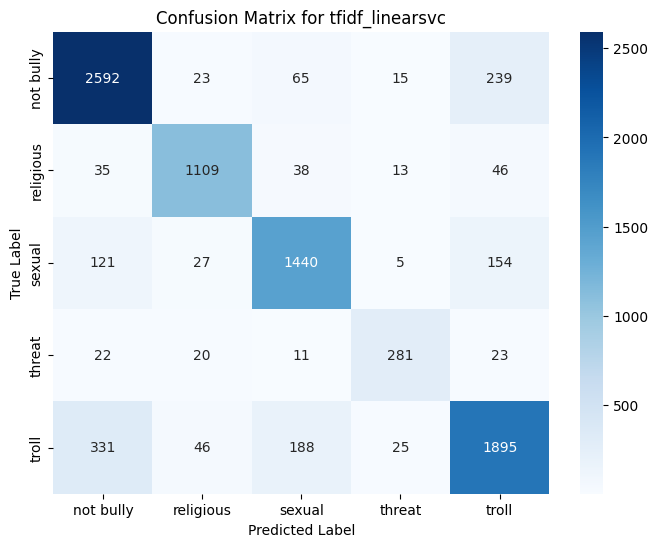

In [ ]:
# Confusion Matrix Heatmap for tfidf_linearsvc
cm_svc = confusion_matrix(yte, predictions_svc, labels=range(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svc, annot=True, fmt='d', cmap='Blues',
            xticklabels=id_to_label, yticklabels=id_to_label)
plt.title('Confusion Matrix for tfidf_linearsvc')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(OUTDIR / 'tfidf_linearsvc_confusion_matrix.png')
print(f"Confusion matrix heatmap for tfidf_linearsvc saved to {OUTDIR / 'tfidf_linearsvc_confusion_matrix.png'}")
plt.show()
plt.close()

ROC-AUC curve for tfidf_linearsvc saved to /content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset/tfidf_linearsvc_roc_auc_curve.png


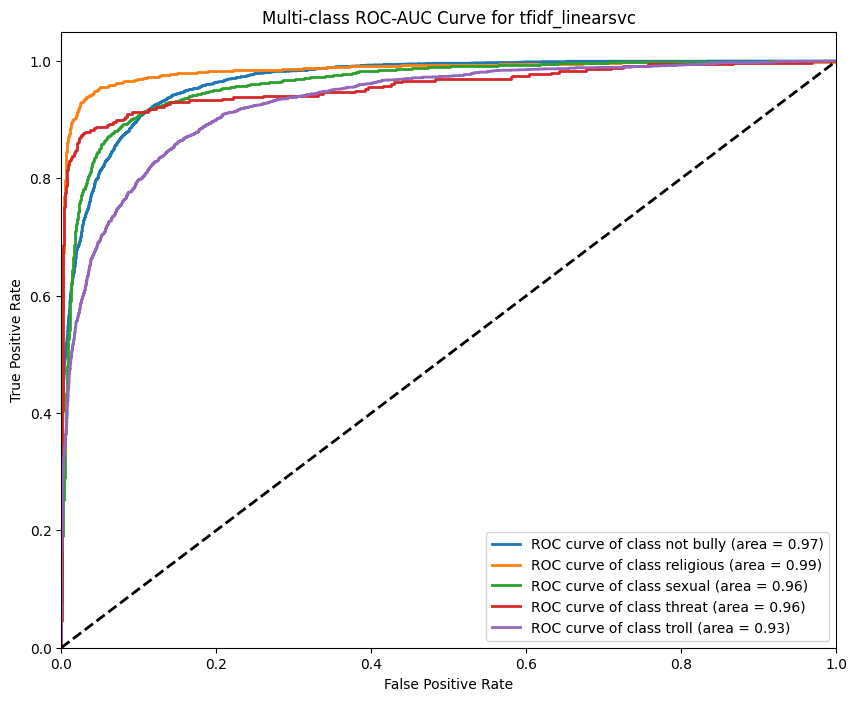

In [ ]:
# ROC-AUC Curve for tfidf_linearsvc

bn_svc = LabelBinarizer()
bn_svc.fit(yte)

y_test_bin_svc = bn_svc.transform(yte)
y_score_svc = PROBS_ML['tfidf_linearsvc']

plt.figure(figsize=(10, 8))
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_test_bin_svc[:, i], y_score_svc[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'ROC curve of class {id_to_label[i]} (area = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC-AUC Curve for tfidf_linearsvc')
plt.legend(loc="lower right")
plt.savefig(OUTDIR / 'tfidf_linearsvc_roc_auc_curve.png')
print(f"ROC-AUC curve for tfidf_linearsvc saved to {OUTDIR / 'tfidf_linearsvc_roc_auc_curve.png'}")
plt.show()
plt.close()

### Evaluation for `tfidf_mnb`

In [ ]:
print("Classification Report for tfidf_mnb:")
predictions_mnb = clf_mnb.predict(Xte)
report_mnb = classification_report(yte, predictions_mnb, target_names=id_to_label, digits=4, zero_division=0)
print(report_mnb)
with open(OUTDIR / 'tfidf_mnb_classification_report.txt', 'w') as f:
    f.write(report_mnb)
print(f"Classification report for tfidf_mnb saved to {OUTDIR / 'tfidf_mnb_classification_report.txt'}")

Classification Report for tfidf_mnb:
              precision    recall  f1-score   support

   not bully     0.8105    0.8528    0.8311      2934
   religious     0.7277    0.8550    0.7862      1241
      sexual     0.7882    0.7006    0.7418      1747
      threat     0.8903    0.3866    0.5391       357
       troll     0.7356    0.7433    0.7394      2485

    accuracy                         0.7727      8764
   macro avg     0.7904    0.7076    0.7275      8764
weighted avg     0.7763    0.7727    0.7690      8764

Classification report for tfidf_mnb saved to /content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset/tfidf_mnb_classification_report.txt


Confusion matrix heatmap for tfidf_mnb saved to /content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset/tfidf_mnb_confusion_matrix.png


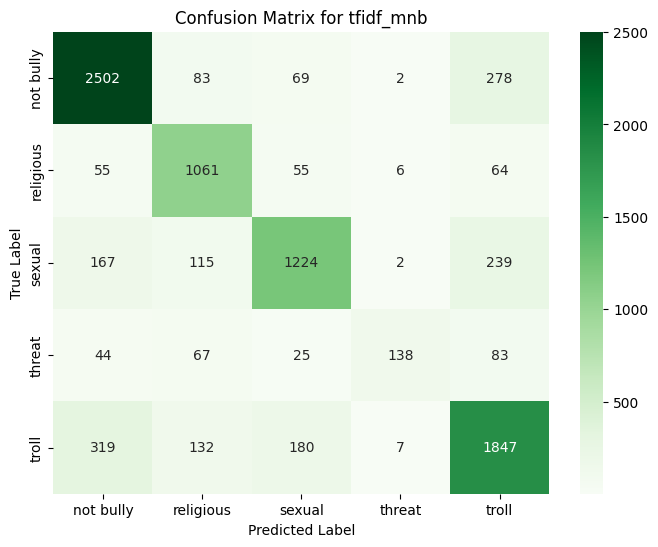

In [ ]:
# Confusion Matrix Heatmap for tfidf_mnb
cm_mnb = confusion_matrix(yte, predictions_mnb, labels=range(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(cm_mnb, annot=True, fmt='d', cmap='Greens',
            xticklabels=id_to_label, yticklabels=id_to_label)
plt.title('Confusion Matrix for tfidf_mnb')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(OUTDIR / 'tfidf_mnb_confusion_matrix.png')
print(f"Confusion matrix heatmap for tfidf_mnb saved to {OUTDIR / 'tfidf_mnb_confusion_matrix.png'}")
plt.show()
plt.close()

ROC-AUC curve for tfidf_mnb saved to /content/drive/MyDrive/dataset/Multiclass_Cyberbulling_dataset/nb_dataset/tfidf_mnb_roc_auc_curve.png


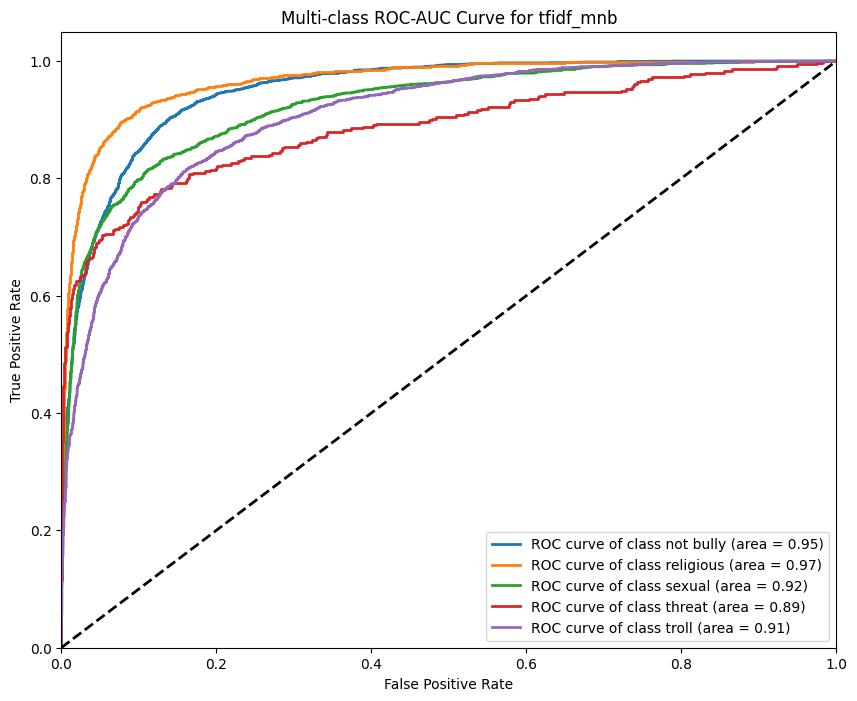

In [ ]:
# ROC-AUC Curve for tfidf_mnb

bn_mnb = LabelBinarizer()
bn_mnb.fit(yte)

y_test_bin_mnb = bn_mnb.transform(yte)
y_score_mnb = PROBS_ML['tfidf_mnb']

plt.figure(figsize=(10, 8))
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_test_bin_mnb[:, i], y_score_mnb[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'ROC curve of class {id_to_label[i]} (area = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC-AUC Curve for tfidf_mnb')
plt.legend(loc="lower right")
plt.savefig(OUTDIR / 'tfidf_mnb_roc_auc_curve.png')
print(f"ROC-AUC curve for tfidf_mnb saved to {OUTDIR / 'tfidf_mnb_roc_auc_curve.png'}")
plt.show()
plt.close()

In [ ]:
# ------------------------------------------------------- 4. save for Table 1
ML = pd.DataFrame(list(RESULTS_ML.values())).sort_values("macro_F1",
                                                         ascending=False)
ML.to_csv(OUTDIR / "classical_runs.csv", index=False)
_maj = float(np.bincount(yte, minlength=NUM_CLASSES).max() / len(yte))
print(f"\n{'='*66}\nclassical baseline summary\n{'='*66}")
print(ML[["model", "test_acc", "macro_F1", "clean_acc", "clean_macro_F1"] +
         [f"F1_{c}" for c in id_to_label]].to_string(index=False))
print(f"\nmajority baseline on these same 8,764 scored comments: {_maj*100:.2f}%")
print(f"saved -> classical_runs.csv, prob_ml_*_s{SEED}.npy, "
      f"{_MASKF.name}")
print("""
For the paper: two rows under a "Classical" heading in Table 1, plus the clean
column for every arm. The gap between the best classical model and your best
transformer is what justifies the neural pipeline. If that gap is small, say so
plainly. A leakage-audited result showing that TF-IDF is nearly competitive is a
more citable finding than an unaudited result showing BERT wins.""")



classical baseline summary
          model  test_acc  macro_F1  clean_acc  clean_macro_F1  F1_not bully  F1_religious  F1_sexual  F1_threat  F1_troll
tfidf_linearsvc  0.834893  0.834816   0.829937        0.824890      0.858989      0.899432   0.825451   0.807471  0.782734
      tfidf_mnb  0.772707  0.727516   0.771183        0.721797      0.831091      0.786217   0.741818   0.539062  0.739392

majority baseline on these same 8,764 scored comments: 33.48%
saved -> classical_runs.csv, prob_ml_*_s42.npy, test_nearest_train_jaccard.npy

For the paper: two rows under a "Classical" heading in Table 1, plus the clean
column for every arm. The gap between the best classical model and your best
transformer is what justifies the neural pipeline. If that gap is small, say so
plainly. A leakage-audited result showing that TF-IDF is nearly competitive is a
more citable finding than an unaudited result showing BERT wins.


tfidf_linearsvc    micro AUC 0.9674 | macro AUC 0.9602
tfidf_mnb          micro AUC 0.9441 | macro AUC 0.9266


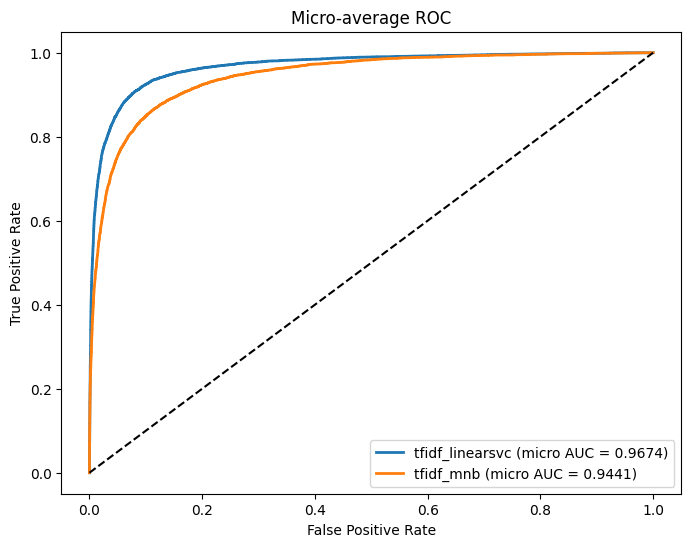

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(yte, classes=range(NUM_CLASSES))

for name in ["tfidf_linearsvc", "tfidf_mnb"]:
    P = PROBS_ML[name]
    micro = roc_auc_score(y_bin, P, average="micro")
    macro = roc_auc_score(y_bin, P, average="macro")
    print(f"{name:18s} micro AUC {micro:.4f} | macro AUC {macro:.4f}")

# Optional: draw the micro-average curve
plt.figure(figsize=(8, 6))
for name in ["tfidf_linearsvc", "tfidf_mnb"]:
    fpr, tpr, _ = roc_curve(y_bin.ravel(), PROBS_ML[name].ravel())
    plt.plot(fpr, tpr, lw=2, label=f"{name} (micro AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Micro-average ROC"); plt.legend(loc="lower right")
plt.show()